# P3 · Acquisition & Integration
**Sean Ryan · sryan3 · DSA 405 (002) · Fall 2026**

**Question:** Which reported ticker–calendar-month combinations occur in the archived House and Senate disclosure sources during transaction year 2025?

This independent repository extracts its House PDFs and reparses archived official Senate HTML using the code, source files, and review rules bundled here. Its normal build uses its own generated House dataset, with input and output fingerprints checked before reuse. It does not read from Data Portfolio or a sibling repository. The website is a supplementary source/code inspector; this executed notebook is the course deliverable.

**Observed result:** 6,394 in-scope House report rows and 518 Senate report rows form 3,760 ticker-month keys: 160 in both sources, 3,410 House-only, and 190 Senate-only. These are coverage observations about unequal, incomplete archives, not a census of actual trading. Amendments remain separate reported records.

**Run order:** Setup → acquisition → source parsing → ethics/drift → join design **before** the merge → verification → finding → self-assessment. Default execution is offline. Optional network acquisition is explicit and never submits a Senate agreement.

## 0. Setup and independent inputs
Run from the repository or its `notebooks/` directory. Install `requirements.txt` in a Python 3.12 environment first.

**Colab:** This repository is private. Download the repository ZIP (or the supplied `P3-project.zip`) while signed in, then run this cell and upload that ZIP when prompted. The cell extracts the project safely and installs its declared dependencies in Colab. No GitHub token belongs in this notebook.

In [1]:
from pathlib import Path
import sys, json, hashlib, zipfile, subprocess, importlib.util

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "P3"]
ROOT = next((p for p in candidates if (p / "scripts/integration.py").is_file()), None)
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if ROOT is None and IN_COLAB:
    from google.colab import files
    uploads = files.upload()
    archives = [name for name in uploads if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload exactly one P3 project ZIP, containing scripts/ and data/raw/.")
    destination = Path("/content/p3_uploaded_project")
    destination.mkdir(exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError("Unsafe ZIP member path")
        archive.extractall(destination)
    ROOT = next((p.parent.parent for p in destination.rglob("scripts/integration.py")), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete P3 repository, or upload its ZIP in Colab.")
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")])
sys.path.insert(0, str(ROOT / "scripts"))
import pandas as pd
from IPython.display import display, Code, HTML, SVG
from integration import (verify_raw, load_house, prepare_comparable, aggregate,
                         join_design, merge_summaries, verify_join, demonstrate_real_data_failures)
from senate import parse_archive, find_table, SourceStructureError
from acquisition import CachedFetcher, acquisition_plan, USER_AGENT
from build_site import failure_cases
print("Project root located. Python", sys.version.split()[0])
print("Unchanged original raw files verified:", verify_raw(ROOT))
display(pd.DataFrame(json.loads((ROOT / "provenance/source_commits.json").read_text())).T)


Project root located. Python 3.12.14
Unchanged original raw files verified: 1105


,commit
P2,429c32a23a9d3236f59df1a94a321fbc0054afb1
Senate,611e7ff2ffe5a26b9b5d2a6978cc4a5c85cf8d37
Portfolio,f93fbbebc6f281f70f76f8c61fc94dd942ffe70f


## 1. Acquisition code
The source inventory is fixed, with 515 archived House PDFs and 583 Senate HTML filings. A finite inventory has no pagination; all 1,098 document URLs are enumerated. The original Senate live-search pagination code is retained for provenance in `provenance/senate_scraper_original.py`; this version does not run that agreement-gated search.

`CachedFetcher` identifies the requests as noncommercial coursework, waits at least one second between requests, uses a 30-second timeout, stops on non-200/empty responses, verifies cached hashes, and remembers both successes and failures for the run. The default parser reads `data/raw/`; optional `python scripts/acquisition.py --chamber Senate --limit 1` retrieves the pinned public archive copy. House URLs point to official PDFs.

The static-file downloads are **not API calls**. Safe response headers are archived, including rate-limit headers if the server supplies them; no documented API limit is assumed. The Senate acquisition path uses previously collected source HTML rather than silently accepting an access agreement. Windows text checkout CRLF bytes and GitHub raw LF transport bytes have separate documented hashes; archived inputs are not rewritten.

In [2]:
import inspect
# These are the exact implementations used, displayed here for grading.
print("User-Agent:", USER_AGENT)
display(Code(inspect.getsource(CachedFetcher), language="python"))
plan = acquisition_plan()
print("Enumerated source documents:", len(plan))
assert len(plan) == 1098  # protects against a missing document inventory
sample = next(row for row in plan if "/senate/" in row["path"])
client = CachedFetcher()
body = client.fetch(sample["url"])
assert hashlib.sha256(body).hexdigest() == sample["sha256"]
assert client.fetch(sample["url"]) == body  # same URL reuses memory
assert all(event["from"] != "network" for event in client.events)
print("Offline repeat-run proof:", [event["from"] for event in client.events])
header_rows = []
for path in (ROOT / "data/raw/http_cache").glob("*.json"):
    meta = json.loads(path.read_text())
    rate_headers = {k:v for k,v in meta["headers"].items() if "ratelimit" in k.lower() or k.lower() == "retry-after"}
    header_rows.append({"status":meta["status"],"source":meta["url"],
                        "observed rate-limit headers":rate_headers or "none returned (static file)",
                        "retrieved UTC":meta["retrieved_at_utc"]})
display(pd.DataFrame(header_rows))


User-Agent: DSA405-P3-Coursework/1.0 (Sean Ryan; noncommercial academic acquisition)


class CachedFetcher:
    def __init__(self, cache_dir=None, interval=1.0, opener=None, clock=time.monotonic, sleep=time.sleep):
        if interval < 1.0:
            raise ValueError('Coursework rate limit must be at least one second.')
        self.cache_dir = Path(cache_dir or ROOT/'data/raw/http_cache')
        self.cache_dir.mkdir(parents=True, exist_ok=True)
        self.interval, self.clock, self.sleep = interval, clock, sleep
        self.opener = opener or urllib.request.build_opener()
        self.last_request = None
        self.seen = {}
        self.events = []

    def fetch(self, url):
        # Both successful and failed attempts are memoized: no repeated resource in a run.
        if url in self.seen:
            result = self.seen[url]
            if isinstance(result, Exception): raise result
            self.events.append({'url':url,'from':'memory'})
            return result
        key = hashlib.sha256(url.encode()).hexdigest()
        body_path = self.cache_dir/f'{key}.body'
        meta_path = self.cache_dir/f'{key}.json'
        if body_path.exists() and meta_path.exists():
            body = body_path.read_bytes()
            meta = json.loads(meta_path.read_text(encoding='utf-8'))
            if hashlib.sha256(body).hexdigest() != meta['sha256']:
                raise AcquisitionError(f'Cache checksum mismatch for {url}')
            self.seen[url] = body
            self.events.append({'url':url,'from':'disk','sha256':meta['sha256']})
            return body
        if body_path.exists() or meta_path.exists():
            raise AcquisitionError(f'Incomplete cache pair for {url}; inspect it before recovery.')
        if self.last_request is not None:
            self.sleep(max(0, self.interval-(self.clock()-self.last_request)))
        self.last_request = self.clock()
        request = urllib.request.Request(url, headers={'User-Agent':USER_AGENT})
        try:
            with self.opener.open(request, timeout=30) as response:
                status = response.status
                if status != 200: raise AcquisitionError(f'HTTP {status}: {url}')
                body = response.read()
                safe_headers={'content-type','date','etag','last-modified','content-length',
                              'x-ratelimit-limit','x-ratelimit-remaining','x-ratelimit-reset','retry-after'}
                headers = {k:v for k,v in response.headers.items() if k.lower() in safe_headers}
            if not body: raise AcquisitionError(f'Empty response: {url}')
        except (urllib.error.URLError, TimeoutError, OSError, AcquisitionError) as exc:
            error = AcquisitionError(f'Acquisition stopped for {url}: {exc}')
            self.seen[url] = error
            raise error from exc
        meta = {'url':url,'status':status,'headers':headers,'user_agent':USER_AGENT,
                'retrieved_at_utc':datetime.now(timezone.utc).isoformat(),
                'sha256':hashlib.sha256(body).hexdigest()}
        # Exclusive creation prevents a refresh from silently overwriting an archive.
        with body_path.open('xb') as stream: stream.write(body)
        with meta_path.open('x',encoding='utf-8') as stream: json.dump(meta,stream,indent=2)
        self.seen[url] = body
        self.events.append({'url':url,'from':'network','status':status,'sha256':meta['sha256']})
        return body

Enumerated source documents: 1098


Offline repeat-run proof: ['disk', 'memory']


,status,source,observed rate-limit headers,retrieved UTC
0,200,https://raw.githubusercontent.com/Strokeofluck...,none returned (static file),2026-10-23T20:33:06.594632+00:00
1,200,https://disclosures-clerk.house.gov/public_dis...,none returned (static file),2026-10-23T20:37:42.554154+00:00


### Demonstrate a loud failure
A maintenance page is valid HTML but not a transaction table. Continuing would silently produce an empty dataset. The remaining demonstrations use copies of P3's actual summaries: duplicate a Senate key, drop an unmatched result row, and change a House report count. The same real-data mutations are shown beside the verification suite in Section 5.

In [3]:
caught = failure_cases()
assert {case["caught"] for case in caught} == {"SourceStructureError", "MergeError", "AssertionError"}
for case in caught:
    print(case["title"], "→", case["caught"] + ":", case["message"])
assert len(caught) == 4
print("All four deliberately broken inputs were caught; no bad output was accepted.")


Missing HTML selector → SourceStructureError: Expected Senate transaction table matched nothing, or its headers changed.
Duplicate real Senate summary key → MergeError: Merge keys are not unique in right dataset; not a one-to-one merge
Drop one real unmatched ticker-month → AssertionError: Protects against fan-out or dropped keys
Increase one real House report count → AssertionError: Protects against lost or multiplied House report rows
All four deliberately broken inputs were caught; no bad output was accepted.


## 2. Source parsing and comparable scope
**House:** P3 builds `data/processed/house_extracted.csv` from the 515 PDFs, pinned parser, ticker-cleaning code, and checked review decisions inside this repository. Its 7,667 rows are generated by this project rather than loaded from P2's finished CSV. A source/code signature and output checksum protect the committed cache. Run `python scripts/house.py --rebuild` to reparse every PDF in a new local workspace; the default build automatically regenerates a missing or outdated extract. The first full PDF rebuild takes several minutes. Earlier projects are credited as the origin of the preserved archive and code.

**Senate:** parse every one of the 583 archived electronic reports. Require the nine expected HTML headers and nine cells per transaction row. Missing tables, dates, amounts, files, and duplicate report/item identities stop the pipeline. The filing index keeps 97 deferred paper reports visible.

**Comparable population:** transaction dates in 2025, reported stock/fund records (`ST` for House; `Stock` for Senate), usable reported ticker text, and House resolver status `accepted`. Preserve all exclusions in a separate table. Preserve report-level identities and source URLs; keep amendments. Funds/ETFs can appear under these source labels. Ticker text is not a permanent security identifier, so overlap is descriptive rather than proof that securities are economically identical.

In [4]:
house_all = load_house(ROOT)
house_build = json.loads((ROOT / "data/processed/house_extraction.json").read_text())
assert house_build["rows"] == len(house_all)
print("P3 House extraction:", house_build["rows"], "rows from", house_build["parsed_filings"], "parsed filings")
print("All", house_build["recipe"]["pdf_count"], "bundled PDFs accounted for;", house_build["filings_without_rows"], "have no extracted rows")
print("Checked local review corrections:", house_build["review"]["changed_cells"], "value cells")
senate_all, senate_coverage = parse_archive(ROOT)
# Confirm the new strict parser reproduces the upstream archive's record identities and fields.
upstream = pd.read_csv(ROOT / "data/raw/senate/transactions_upstream.csv", dtype=str, keep_default_na=False)
upstream["row_key"] = upstream.report_id + ":" + upstream.item_number
audit_new = senate_all.assign(row_key=senate_all.filing_id + ":" + senate_all.row_number)
assert upstream.row_key.is_unique and audit_new.row_key.is_unique
assert set(upstream.row_key) == set(audit_new.row_key)
audit = audit_new.merge(upstream, on="row_key", validate="one_to_one", suffixes=("_new", "_upstream"))
for column in ["transaction_date", "ticker", "asset_name", "transaction_type"]:
    # Upstream converts the source placeholder -- to blank; the strict parser
    # retains it as evidence. Normalize ONLY that documented placeholder here.
    parsed_values = audit[column+"_new"].fillna("").replace({"--":""})
    assert parsed_values.eq(audit[column+"_upstream"].fillna("")).all(), column
print("Source ticker placeholder -- retained in", int(audit.ticker_new.eq("--").sum()), "rows; upstream stored these as blanks.")
house, house_excluded, house_counts = prepare_comparable(house_all, "House")
senate, senate_excluded, senate_counts = prepare_comparable(senate_all, "Senate")
display(pd.DataFrame([house_counts, senate_counts], index=["House", "Senate"]))
print("Senate filing coverage:", senate_coverage)
print("All 5,069 Senate parsed records reconcile to the upstream archived table.")


P3 House extraction:

 7667 rows from 449 parsed filings
All 515 bundled PDFs accounted for; 66 have no extracted rows
Checked local review corrections: 2 value cells


Source ticker placeholder -- retained in 1625 rows; upstream stored these as blanks.


,input_rows,eligible_rows,outside_year,excluded_scope,excluded_ticker
House,7667,6394,504,765,4
Senate,5069,518,4230,255,66


Senate filing coverage: {'electronic_reports': 583, 'paper_reports_deferred': 97, 'index_rows': 680, 'parsed_rows': 5069}
All 5,069 Senate parsed records reconcile to the upstream archived table.


## 3. Ethics and A8 plan drift
Compared with `DSA405_002_FA26_A8_sryan3.ipynb`, submitted to Moodle on October 14, 2026. A8 names **House + Senate disclosures** and records that Sean asked the instructor about these sources and received approval. P3 retains that topic and the public-official disclosure scope; it does not claim that topic approval establishes an unrestricted license or automated-access permission.

| A8 plan | P3 implementation and reason for drift |
|---|---|
| Reuse archives; obtain missing official PDFs and Senate HTML through the normal agreement/session flow | Reuse frozen archives by default. Optional House acquisition uses official PDF URLs; Senate acquisition retrieves exact-commit archive copies. This avoids repeating an agreement-gated live search and keeps the build reproducible offline. The original collector remains attributed. |
| October 14 snapshot: 581 electronic Senate filings and 5,052 rows | P3 pins the October 22 archive: 583 electronic filings and 5,069 rows. The 97 deferred paper reports remain an explicit gap. Snapshot growth is not a claim of completeness. |
| At least two seconds between requests | P3 uses the brief's one-second minimum, with one request at a time, caching, timeouts and loud errors. Denied requests are not automatically retried. The default build makes no source requests. This rate change is documented rather than described as an exact match to A8. |
| Standardize transactions and compare chambers | Aggregate each chamber to one row per ticker-month before a one-to-one outer join. Different legislators cannot be matched across chambers, and repeated raw ticker-month rows would multiply. Keep the transaction append separate. |

**Guardrails:** no account login, paywall, CAPTCHA solving, circumvention, or submission of the Senate access agreement is performed by P3. Public reports still contain names and disclosed financial interests, so the assignment's “no personal data” language cannot honestly be described as literal absence of personal information. The intended scope is the public-official disclosure topic recorded as instructor-approved in A8, for noncommercial coursework; omit unrelated private identifiers and make no credit, solicitation, or wrongdoing inference.

The [Senate access notice](https://efdsearch.senate.gov/search/home/) lists restrictions on report use. The [House Clerk](https://disclosures-clerk.house.gov/FinancialDisclosure) is the official House source. This notebook records the scope and access path; it does not claim a legal determination or that a previous agreement grants new consent.

**Coverage:** The captured House archive has 515 PDFs, 449 with extracted rows and 66 without extracted rows. Senate has 583 electronic and 97 deferred paper reports across the index's 2021–2026 filing window. Their collection dates differ. Amount ranges are not exact amounts, and amendments may repeat economic events.

## 4. Join design — before writing the merge
**Do not merge transaction rows directly on ticker and month.** That would create a many-to-many multiplication when both chambers report several rows for the same ticker-month. Summarize each source first.

| Design item | Decision |
|---|---|
| Keys | reported ticker + calendar month, within 2025 |
| Left grain | one ticker-month in the House archive |
| Right grain | one ticker-month in the Senate electronic archive |
| Relationship | one-to-one after aggregation |
| Expected rows | **3,760**, independently counted as the union of key sets |
| Join type | outer: compare both sources while keeping unmatched keys |
| Unmatched values | retained with NA in the absent chamber; not filled with zero |

An inner join would discard 3,600 keys. Joining legislators across chambers does not answer this question. An append produces a common transaction table but does not compare the source summaries or prove join cardinality.

In [5]:
house_summary = aggregate(house, "house")
senate_summary = aggregate(senate, "senate")
design = join_design(house_summary, senate_summary)
display(pd.DataFrame([design]).T.rename(columns={0:"Declared before merge"}))
assert design["expected_rows"] == 3760  # protects the frozen snapshot's expected union size
assert len(house_summary) == 3570 and len(senate_summary) == 350


,Declared before merge
keys,"[ticker, month]"
left_grain,one row per ticker and calendar month in House...
right_grain,one row per ticker and calendar month in Senat...
relationship,one_to_one
join_type,outer
expected_rows,3760
left_rows,3570
right_rows,350
both,160
left_only,3410


### Run the declared merge
`validate=` rejects fan-out caused by duplicate summary keys. The union assertion in the next section independently rejects row loss from an accidental inner join.

In [6]:
joined = house_summary.merge(
    senate_summary,
    on=["ticker", "month"],
    how="outer",
    validate="one_to_one",
    indicator=True,
).sort_values(["ticker", "month"]).reset_index(drop=True)
display(joined.head(8))


,ticker,month,house_reports,house_filings,house_filers,house_purchases,house_sales,senate_reports,senate_filings,senate_filers,senate_purchases,senate_sales,_merge
0,A,2025-03,2.0,2.0,2.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN,left_only
1,A,2025-04,3.0,3.0,3.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,left_only
2,A,2025-05,2.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,left_only
3,A,2025-06,1.0,1.0,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,left_only
4,A,2025-07,1.0,1.0,1.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,left_only
5,AAL,2025-03,5.0,1.0,1.0,4.0,1.0,NaN,NaN,NaN,NaN,NaN,left_only
6,AAL,2025-04,6.0,1.0,1.0,6.0,0.0,NaN,NaN,NaN,NaN,NaN,left_only
7,AAL,2025-05,1.0,1.0,1.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,left_only


## 5. Verification suite
Each assertion protects a real assumption. These checks cover both unwanted row multiplication and lost unmatched records. The function is included in the repository and shown in full below.

In [7]:
display(Code(inspect.getsource(verify_join), language="python"))
checks = verify_join(joined, house_summary, senate_summary, design, house, senate)
for index, description in enumerate(checks, 1):
    print(f"PASS {index}: {description}")
assert verify_raw(ROOT) == 1105  # protects untouched original raw inputs
# Run the separate timeout, HTTP, cache, rate-limit, and deliberate join-failure tests too.
test_run = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", str(ROOT / "tests"), "-v"], capture_output=True, text=True)
print(test_run.stderr.strip())
assert test_run.returncode == 0, "Reliability tests failed"


def verify_join(joined,house,senate,design,house_transactions,senate_transactions):
    # Each assertion states the real data assumption it protects.
    assert len(joined)==design['expected_rows'],'Protects against fan-out or dropped keys'
    assert not joined.duplicated(KEYS).any(),'Protects against duplicated ticker-month summaries'
    assert set(map(tuple,joined[KEYS].to_numpy()))==(set(map(tuple,house[KEYS].to_numpy()))|set(map(tuple,senate[KEYS].to_numpy()))),'Protects against an accidental inner join dropping unmatched months'
    assert int(joined.house_reports.sum())==len(house_transactions),'Protects against lost or multiplied House report rows'
    assert int(joined.senate_reports.sum())==len(senate_transactions),'Protects against lost or multiplied Senate report rows'
    assert joined[KEYS].notna().all().all(),'Protects against missing merge keys matching each other'
    assert joined.month.str.fullmatch(r'2025-(0[1-9]|1[0-2])').all(),'Protects against joining different analysis years'
    for prefix in ['house','senate']:
        values=joined[f'{prefix}_reports'].dropna()
        assert (values.ge(1)&values.mod(1).eq(0)).all(),'Protects against impossible report counts'
    assert int(joined._merge.eq('both').sum())==design['both'],'Protects against changed overlap cardinality'
    return ['Expected union row count','Unique ticker-month keys','All unmatched keys retained',
        'House report-count conservation','Senate report-count conservation','Nonmissing join keys',
        'Valid 2025 months','Positive integer counts','Expected overlap cardinality']

PASS 1: Expected union row count
PASS 2: Unique ticker-month keys
PASS 3: All unmatched keys retained
PASS 4: House report-count conservation
PASS 5: Senate report-count conservation
PASS 6: Nonmissing join keys
PASS 7: Valid 2025 months
PASS 8: Positive integer counts
PASS 9: Expected overlap cardinality


test_altered_generated_cache_is_rejected_without_silent_rebuild (test_house.HouseExtractionTests.test_altered_generated_cache_is_rejected_without_silent_rebuild) ... ok
test_changed_review_evidence_is_rejected (test_house.HouseExtractionTests.test_changed_review_evidence_is_rejected) ... ok
test_pipeline_reads_own_extract_not_the_finished_p2_table (test_house.HouseExtractionTests.test_pipeline_reads_own_extract_not_the_finished_p2_table) ... ok
test_review_cannot_target_missing_or_duplicated_identity (test_house.HouseExtractionTests.test_review_cannot_target_missing_or_duplicated_identity) ... ok
test_review_preserves_evidence_and_original_flags (test_house.HouseExtractionTests.test_review_preserves_evidence_and_original_flags) ... ok
test_cache_memory_disk_and_honest_agent (test_pipeline.AcquisitionTests.test_cache_memory_disk_and_honest_agent) ... ok
test_corrupt_cached_body_is_rejected (test_pipeline.AcquisitionTests.test_corrupt_cached_body_is_rejected) ... ok
test_requests_are_spa

### Prove the suite catches changes to the real data
These are copies of the actual House and Senate summaries and the actual joined result, not invented ticker examples. Duplicate one real Senate key to demonstrate the cardinality check. Then run the same verification suite on a copy with one unmatched row removed and a copy with one House report count increased. The latter keeps the row count unchanged, so a different data assumption must catch it. Print each caught exception and verify that the originals and raw files are unchanged.

In [8]:
original_frames = [frame.copy(deep=True) for frame in (joined, house_summary, senate_summary)]
real_failures = demonstrate_real_data_failures(joined, house_summary, senate_summary, design, house, senate)
for case in real_failures:
    print(case["title"])
    print("CAUGHT", case["caught"] + ":", case["message"])
    if "changed_key" in case:
        print("Actual key copied:", case["changed_key"])
    else:
        print("Rows: original", case["original_rows"], "mutated", case["mutated_rows"])
assert len(real_failures) == 3  # protects against a demonstration silently not running
for original, current in zip(original_frames, (joined, house_summary, senate_summary)):
    pd.testing.assert_frame_equal(original, current)
assert verify_raw(ROOT) == 1105
assert len(verify_join(joined, house_summary, senate_summary, design, house, senate)) == 9
print("Original summaries and joined result unchanged; all nine checks still pass.")


Duplicate real Senate summary key
CAUGHT MergeError: Merge keys are not unique in right dataset; not a one-to-one merge
Actual key copied: {'ticker': 'AAPL', 'month': '2025-01'}
Drop one real unmatched ticker-month
CAUGHT AssertionError: Protects against fan-out or dropped keys
Rows: original 3760 mutated 3759
Increase one real House report count
CAUGHT AssertionError: Protects against lost or multiplied House report rows
Rows: original 3760 mutated 3760


Original summaries and joined result unchanged; all nine checks still pass.


## 6. One finding and what it changes
Only **160 of 3,760 ticker-month keys (4.26%) occur in both archives**. An inner join would remove **3,600 keys (95.74%)**. That is why the outer join matters: it preserves the source coverage that an inner join would hide.

The lesson from this check is that a merge can run without errors and still answer a much narrower question than intended. Declaring the expected union first and testing a deliberately damaged copy makes that risk visible. The low overlap does not establish that the chambers' actual investments differ by that amount, because coverage, filings, amendments, and source formats differ.

,Unique ticker-month keys
_merge,
House only,3410
Senate only,190
Both chambers,160


Overlap: 4.26%
Keys an inner join would lose: 3,600


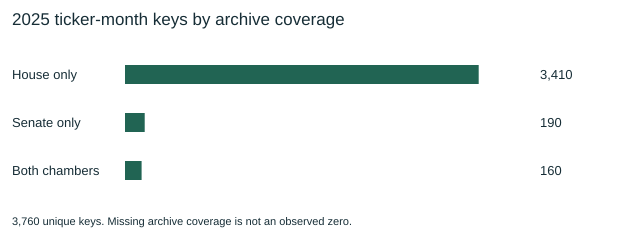

In [9]:
coverage = joined["_merge"].value_counts().reindex(["left_only", "right_only", "both"])
display(coverage.rename(index={"left_only":"House only", "right_only":"Senate only", "both":"Both chambers"}).to_frame("Unique ticker-month keys"))
print(f"Overlap: {design['both'] / design['expected_rows']:.2%}")
print(f"Keys an inner join would lose: {design['left_only'] + design['right_only']:,}")
# A static, directly labeled count diagram; widths use a shared zero-based scale.
labels = [("House only",design["left_only"]),("Senate only",design["right_only"]),("Both chambers",design["both"])]
bars = []
for i, (label, count) in enumerate(labels):
    y = 65 + i*48
    bars.append(f'<text x="12" y="{y+14}" font-size="13">{label}</text><rect x="125" y="{y}" width="{count/design["expected_rows"]*390}" height="19" fill="#216453"/><text x="540" y="{y+14}" font-size="13">{count:,}</text>')
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 620 240" width="620" role="img" aria-label="House only 3410; Senate only 190; both chambers 160 ticker-month keys"><rect width="620" height="240" fill="white"/><g font-family="Arial" fill="#162d36"><text x="12" y="25" font-size="17">2025 ticker-month keys by archive coverage</text>' + ''.join(bars) + '<text x="12" y="225" font-size="11">3,760 unique keys. Missing archive coverage is not an observed zero.</text></g></svg>'))


## 7. Write reproducible outputs
The exclusion table accounts for every original row; source identities and URLs remain available. The interactive website is built from these same functions and output schemas.

In [10]:
output = ROOT / "data/processed"
output.mkdir(parents=True, exist_ok=True)
joined.to_csv(output / "combined_ticker_month.csv", index=False)
combined = pd.concat([house, senate.drop(columns="row_key",errors="ignore")], ignore_index=True)
assert combined.transaction_id.is_unique
combined.to_csv(output / "combined_transactions.csv", index=False)
pd.concat([house_excluded, senate_excluded], ignore_index=True).to_csv(output / "excluded_rows.csv", index=False)
print(f"Saved {len(joined):,} summary rows and {len(combined):,} comparable source rows.")
print("Raw inputs still verified:", verify_raw(ROOT))


Saved 3,760 summary rows and 6,912 comparable source rows.


Raw inputs still verified: 1105


## 8. Self-scored rubric
| Criterion | Weight | Self-score (1–4) | Evidence / limit |
|---|---:|---:|---|
| Acquisition code | ×2 | 4 | explicit URL inventory, one-second throttle, honest agent, immutable cache, headers, timeouts/errors, demonstrated selector catch |
| Ethics & legality in practice | ×2 | 4 | compared with submitted A8; source approval recorded there; snapshot, access and rate changes explained; public personal information and use limits disclosed |
| Join design | ×2 | 4 | grain, keys, cardinality, expected numeric count, unmatched policy and alternatives stated before merge |
| Verification suite | ×3 | 4 | nine data assumptions, upstream reconciliation, twelve reliability tests, and caught mutations of the actual project data |
| Reproducibility & readability | ×1 | 4 | self-contained archives and code, pinned environment, restarted execution, README, source inspector |

Sean's requested self-score is **4 on every criterion**: weighted total **40/40**, weighted mean **4.0**, converted to **100%** by the course rubric. This is a self-assessment, not an instructor-awarded grade. See `SELF_ASSESSMENT.md` for the evidence and documented limits. No Moodle submission has been made by this build.